# Valuation-to-Option Pricing and Greeks Lab: Lockheed Martin (LMT)

**Contract analysed:** LMT June 17, 2027 $580 American put (`LMT270617P00580000`), contract multiplier 100.
**Valuation date:** November 9, 2026 (spot and option quotes captured at the same time, about 12:35 PM ET).

| Version | What it adds | Where |
|---|---|---|
| v1: initial model | Course template: continuous dividend yield, 200-step CRR, five analyst states | Sections 1–8 (template code, unchanged except blank-safe DCF/comps inputs) |
| v2: model improvement | Discrete, dated LMT dividends (escrowed-dividend CRR), American-exercise checks, implied volatility, horizon-alignment test | Section 9 |
| v3: Module 5 Greeks | Delta, gamma, vega, theta, rho; finite-difference validation; delta-gamma and multi-factor approximations; sensitivity grids; decision memo | Sections 10–15 |

# Valuation-to-Option Pricing Lab

This notebook keeps two valuation tracks separate:

1. **Analyst-scenario discounted expected payoff:** five terminal equity-value scenarios with subjective weights.
2. **CRR risk-neutral lattice value:** a no-arbitrage option-pricing model built through repeated two-state replication.

The five analyst scenarios are not an expanded binomial tree and are not risk-neutral probabilities. They answer a different question: *Given these valuation beliefs and weights, what is the discounted expected option payoff?*

## 1. Load and validate student inputs

In [1]:
from pathlib import Path
import json, numpy as np, pandas as pd
ROOT=Path.cwd(); DATA=ROOT/'data'; DOCS=ROOT/'docs'; DOCS.mkdir(exist_ok=True)
inputs=pd.read_csv(DATA/'company_inputs.csv')
if len(inputs)!=1: raise ValueError('company_inputs.csv must contain exactly one firm row.')
M=inputs.iloc[0].to_dict()
for k in ['spot','strike','maturity_years','risk_free_rate','dividend_yield','volatility','market_bid','market_ask']: M[k]=float(M[k])
# Student valuation inputs may be left blank until entered; blanks are exported as null, never as 0.
for k in ['dcf_value','comps_value']: M[k]=None if pd.isna(M[k]) or str(M[k]).strip()=='' else float(M[k])
if M['dcf_value'] is None: print('WARNING: dcf_value is blank. Enter the DCF equity value per diluted share in data/company_inputs.csv.')
M['lattice_steps']=int(M['lattice_steps']); M['market_mid']=(M['market_bid']+M['market_ask'])/2
M['option_type']=str(M['option_type']).lower(); M['exercise_style']=str(M['exercise_style']).lower()
if not 0<=M['risk_free_rate']<=1: raise ValueError('Enter risk_free_rate in decimal form, such as 0.045.')
if not 0<M['volatility']<=3: raise ValueError('Enter volatility in decimal form, such as 0.28.')
if M['market_bid']>M['market_ask']: raise ValueError('market_bid cannot exceed market_ask.')
if M['option_type'] not in ['call','put']: raise ValueError('option_type must be call or put.')
if M['exercise_style'] not in ['european','american']: raise ValueError('exercise_style must be european or american.')
targets=pd.read_csv(DATA/'analyst_targets.csv')
if len(targets)<5: raise ValueError('At least five analyst targets are required.')
if not targets.target.gt(0).all(): raise ValueError('Analyst targets must be positive.')
if targets.horizon_months.nunique()!=1: raise ValueError('All analyst targets must use one horizon.')
M

{'company': 'Lockheed Martin Corporation',
 'ticker': 'LMT',
 'valuation_date': '2026-11-09',
 'spot': 586.63,
 'strike': 580.0,
 'maturity_years': 0.6027,
 'risk_free_rate': 0.0416,
 'dividend_yield': 0.0245,
 'volatility': 0.3036,
 'volatility_type': 'implied',
 'option_type': 'put',
 'exercise_style': 'american',
 'lattice_steps': 200,
 'market_bid': 48.7,
 'market_ask': 51.6,
 'dcf_value': None,
 'comps_value': None,
 'market_mid': 50.150000000000006}

## 2. Equity valuation and analyst distribution

In [2]:
stats={'count':int(len(targets)),'mean':float(targets.target.mean()),'median':float(targets.target.median()),'std':float(targets.target.std(ddof=1)),'min':float(targets.target.min()),'max':float(targets.target.max())}
valuation={'Current market':M['spot'],'Comparable companies':M['comps_value'],'Student DCF':M['dcf_value'],'Analyst median':stats['median']}
valuation={k:v for k,v in valuation.items() if v is not None}  # omit blank student inputs instead of plotting them as $0
pd.Series(valuation)

Current market    586.63
Analyst median    650.00
dtype: float64

## 3. Five analyst-informed valuation states

The state prices are reproducible quantiles of the analyst-target distribution. The weights are disclosed subjective scenario masses, not risk-neutral probabilities.

- Severe bear: 5th percentile, 10% weight
- Bear: 25th percentile, 20% weight
- Base: 50th percentile, 40% weight
- Bull: 75th percentile, 20% weight
- Tail: 95th percentile, 10% weight

In [3]:
quantile_map={'Severe bear':.05,'Bear':.25,'Base':.50,'Bull':.75,'Tail':.95}
weights={'Severe bear':.10,'Bear':.20,'Base':.40,'Bull':.20,'Tail':.10}
states=pd.DataFrame({
    'state':list(quantile_map),
    'quantile':list(quantile_map.values()),
    'terminal_price':[float(targets.target.quantile(q)) for q in quantile_map.values()],
    'subjective_weight':[weights[k] for k in quantile_map]
})
assert np.isclose(states.subjective_weight.sum(),1.0)
states

,state,quantile,terminal_price,subjective_weight
0,Severe bear,0.05,562.8,0.1
1,Bear,0.25,600.0,0.2
2,Base,0.50,650.0,0.4
3,Bull,0.75,696.0,0.2
4,Tail,0.95,714.7,0.1


## 4. Analyst-scenario payoff decomposition

In [4]:
def payoff(stock,strike,kind):
    stock=np.asarray(stock,float)
    return np.maximum(stock-strike,0) if kind=='call' else np.maximum(strike-stock,0)
states['option_payoff']=payoff(states.terminal_price,M['strike'],M['option_type'])
states['weighted_payoff']=states.subjective_weight*states.option_payoff
weighted_terminal_payoff=float(states.weighted_payoff.sum())
discount_factor=float(np.exp(-M['risk_free_rate']*M['maturity_years']))
belief_value=discount_factor*weighted_terminal_payoff
weight_positive=float(states.loc[states.option_payoff>0,'subjective_weight'].sum())
weight_zero=1-weight_positive
print(f'Weight producing zero payoff: {weight_zero:.1%}')
print(f'Weight producing positive payoff: {weight_positive:.1%}')
print(f'Weighted terminal payoff: ${weighted_terminal_payoff:,.2f}')
print(f'Discount factor: {discount_factor:.4f}')
print(f'Analyst-scenario discounted expected payoff: ${belief_value:,.2f}')
states

Weight producing zero payoff: 90.0%
Weight producing positive payoff: 10.0%
Weighted terminal payoff: $1.72
Discount factor: 0.9752
Analyst-scenario discounted expected payoff: $1.68


,state,quantile,terminal_price,subjective_weight,option_payoff,weighted_payoff
0,Severe bear,0.05,562.8,0.1,17.2,1.72
1,Bear,0.25,600.0,0.2,0.0,0.00
2,Base,0.50,650.0,0.4,0.0,0.00
3,Bull,0.75,696.0,0.2,0.0,0.00
4,Tail,0.95,714.7,0.1,0.0,0.00


### Interpretation
A low analyst-scenario value is intuitive when much of the assigned weight ends below the call strike or above the put strike. The payoff contribution is visible state by state. This is not a replication price.

## 5. CRR risk-neutral lattice

In [5]:
def crr(spot,strike,T,r,sigma,N,q=0,kind='call',american=False):
    dt=T/N; u=np.exp(sigma*np.sqrt(dt)); d=1/u; growth=np.exp((r-q)*dt); p=(growth-d)/(u-d); disc=np.exp(-r*dt)
    if not(d<growth<u and 0<p<1): raise ValueError('No-arbitrage condition failed.')
    j=np.arange(N+1); stock=spot*u**j*d**(N-j); values=payoff(stock,strike,kind)
    for n in range(N-1,-1,-1):
        values=disc*(p*values[1:n+2]+(1-p)*values[:n+1])
        if american:
            j=np.arange(n+1); stock=spot*u**j*d**(n-j); values=np.maximum(values,payoff(stock,strike,kind))
    return {'price':float(values[0]),'u':float(u),'d':float(d),'p_star':float(p),'dt':float(dt)}
lattice=crr(M['spot'],M['strike'],M['maturity_years'],M['risk_free_rate'],M['volatility'],M['lattice_steps'],M['dividend_yield'],M['option_type'],M['exercise_style']=='american')
lattice

{'price': 48.32861462990032,
 'u': 1.0168058861535765,
 'd': 0.98347188349081,
 'p_star': 0.49737947328618226,
 'dt': 0.0030135}

## 6. Theoretical validation and distribution comparison

In [6]:
pvs=M['spot']*np.exp(-M['dividend_yield']*M['maturity_years']); pvk=M['strike']*np.exp(-M['risk_free_rate']*M['maturity_years'])
lo,hi=(max(pvs-pvk,0),pvs) if M['option_type']=='call' else (max(pvk-pvs,0),pvk)
call=crr(M['spot'],M['strike'],M['maturity_years'],M['risk_free_rate'],M['volatility'],M['lattice_steps'],M['dividend_yield'],'call')['price']
put=crr(M['spot'],M['strike'],M['maturity_years'],M['risk_free_rate'],M['volatility'],M['lattice_steps'],M['dividend_yield'],'put')['price']
parity=float((call-put)-(pvs-pvk)); steps=[25,50,100,200,500]
conv=[crr(M['spot'],M['strike'],M['maturity_years'],M['risk_free_rate'],M['volatility'],n,M['dividend_yield'],M['option_type'])['price'] for n in steps]
analyst_log_dispersion=float(np.log(targets.target/M['spot']).std(ddof=1))
vol_horizon_dispersion=float(M['volatility']*np.sqrt(M['maturity_years']))
distribution_message='Analyst targets are narrower than the volatility input used by CRR.' if analyst_log_dispersion<vol_horizon_dispersion else 'Analyst targets are at least as dispersed as the volatility input used by CRR.'
validation={'valid_risk_neutral_probability':bool(0<lattice['p_star']<1),'inside_theoretical_bounds':bool(lo<=lattice['price']<=hi),'put_call_parity_pass':bool(abs(parity)<.05),'convergence_pass':bool(abs(conv[-1]-conv[-2])<.05),'parity_residual':parity,'convergence_gap':float(conv[-1]-conv[-2])}
assert all(validation[k] for k in ['valid_risk_neutral_probability','inside_theoretical_bounds','put_call_parity_pass','convergence_pass'])
print(distribution_message)
validation

Analyst targets are narrower than the volatility input used by CRR.


{'valid_risk_neutral_probability': True,
 'inside_theoretical_bounds': True,
 'put_call_parity_pass': True,
 'convergence_pass': True,
 'parity_residual': -4.995115432393504e-12,
 'convergence_gap': -0.026367923351337197}

## 7. Export dashboard data

In [7]:
results={
 'model':M,'analyst_targets':[float(x) for x in targets.target],'analyst_stats':stats,'valuation':valuation,
 'states':states.to_dict('records'),'valuation_weighted_expected_payoff':belief_value,
 'belief_decomposition':{'weight_zero_payoff':weight_zero,'weight_positive_payoff':weight_positive,'weighted_terminal_payoff':weighted_terminal_payoff,'discount_factor':discount_factor},
 'distribution_comparison':{'analyst_log_dispersion':analyst_log_dispersion,'crr_horizon_volatility':vol_horizon_dispersion,'message':distribution_message},
 'lattice':lattice,'validation':validation,'convergence':[{'steps':n,'price':float(x)} for n,x in zip(steps,conv)],
 'comparison':{'Analyst-scenario discounted expected payoff':belief_value,'CRR risk-neutral lattice value':lattice['price'],'Observed market midpoint':M['market_mid']}
}
(DOCS/'model_results.json').write_text(json.dumps(results,indent=2))
print('Exported docs/model_results.json')
results['comparison']

Exported docs/model_results.json


{'Analyst-scenario discounted expected payoff': 1.6774117338854517,
 'CRR risk-neutral lattice value': 48.32861462990032,
 'Observed market midpoint': 50.150000000000006}

## 8. Decision memo prompt

Explain why the analyst-scenario payoff and CRR value differ. Address the share of scenario weight producing a zero payoff, the contribution from positive-payoff states, the strike, analyst-target dispersion, the CRR volatility input, and why neither estimate should automatically be characterized as the uniquely correct market price.

## 9. Model improvement (v2): discrete, dated dividends

**What changed.** The initial model (Sections 1–8, kept exactly as run) treats LMT's dividend as a continuous yield of 2.45%. LMT actually pays a fixed **$3.60 per quarter**. Three ex-dividend dates fall before the June 17, 2027 expiration: **Dec 1, 2026** (declared), plus **Mar 1, 2027** and **Jun 1, 2027** (estimated from LMT's usual quarterly cycle; see `data/dividends.csv`).

**Why it matters for this contract.** A put gains value when the stock drops on an ex-dividend date. For an *American* put, the timing also changes the early-exercise decision: just before a cash dividend, the holder is better off waiting. A smooth yield spreads the same cash evenly over time and misses both effects.

**Method (escrowed-dividend CRR).** The present value of the dividends paid before expiration is removed from the spot price. The lattice is built on the remaining "risky" component, S* = S − PV(dividends). At every node, the stock price used for the early-exercise test adds back the PV of the dividends still to come. All other inputs (spot, strike, rate, volatility, valuation date) are unchanged, so the only difference between v1 and v2 is how dividends are treated.

**What the improvement affects:** the dividend assumption, the CRR value, the American early-exercise premium, the implied volatility backed out of the market midpoint, the new validation checks below, and every Greek in Sections 10–14 (all of them use the v2 model).

In [8]:
import math
DIV=pd.read_csv(DATA/'dividends.csv')
for col in ['ex_date','amount','status']:
    if col not in DIV.columns: raise ValueError(f'dividends.csv is missing column {col}.')
DIV['ex_date']=pd.to_datetime(DIV['ex_date'],format='%Y-%m-%d')
if not DIV.amount.gt(0).all(): raise ValueError('Dividend amounts must be positive dollars per share.')
VAL_DATE=pd.Timestamp(M['valuation_date'])
EXPIRY=pd.Timestamp('2027-06-17')
CONTRACT_MULTIPLIER=100
T_days=(EXPIRY-VAL_DATE).days
assert abs(T_days/365-M['maturity_years'])<0.001, 'maturity_years must equal calendar days to expiration / 365'

def dividend_schedule(shift_years=0.0, T=None):
    """(time in years from the valuation date, amount) for ex-dates strictly between now and expiration.
    shift_years moves the valuation date forward (used for theta and time-decay repricing)."""
    T=M['maturity_years'] if T is None else T
    t=(DIV.ex_date-VAL_DATE).dt.days/365-shift_years
    keep=(t>0)&(t<T)
    return [(float(a),float(b)) for a,b in zip(t[keep],DIV.amount[keep])]

def pv_dividends(divs,r,t=0.0):
    return sum(D*math.exp(-r*(td-t)) for td,D in divs if td>t+1e-12)

def crr_discrete(spot,strike,T,r,sigma,N,divs,kind='put',american=True,keep_nodes=False):
    """Escrowed-dividend CRR lattice (model v2). Returns price, lattice parameters and, optionally, the first three time steps."""
    divs=[(td,D) for td,D in divs if 0<td<T]
    pv0=pv_dividends(divs,r,0.0); S_star=spot-pv0
    dt=T/N; u=math.exp(sigma*math.sqrt(dt)); d=1/u; growth=math.exp(r*dt); p=(growth-d)/(u-d); disc=1/growth
    if not(d<growth<u and 0<p<1): raise ValueError('No-arbitrage condition failed.')
    j=np.arange(N+1); values=payoff(S_star*u**j*d**(N-j),strike,kind)
    nodes={}; early_nodes=0
    for n in range(N-1,-1,-1):
        values=disc*(p*values[1:n+2]+(1-p)*values[:n+1])
        jj=np.arange(n+1); stock=S_star*u**jj*d**(n-jj)+pv_dividends(divs,r,n*dt)
        if american:
            exercise=payoff(stock,strike,kind); early_nodes+=int((exercise>values+1e-12).sum()); values=np.maximum(values,exercise)
        if keep_nodes and n<=2: nodes[n]=(stock.copy(),values.copy())
    return {'price':float(values[0]),'u':u,'d':d,'p_star':p,'dt':dt,'S_star':S_star,'pv_dividends':pv0,'early_exercise_nodes':early_nodes,'nodes':nodes}

V2_STEPS=500
def v2_price(spot=None,sigma=None,r=None,shift_years=0.0,N=V2_STEPS,american=True,kind=None):
    """Model-v2 value: average of the N- and (N+1)-step lattices, which removes most of the odd/even oscillation of CRR."""
    spot=M['spot'] if spot is None else spot; sigma=M['volatility'] if sigma is None else sigma
    r=M['risk_free_rate'] if r is None else r; kind=M['option_type'] if kind is None else kind
    T=M['maturity_years']-shift_years; divs=dividend_schedule(shift_years,T)
    return 0.5*(crr_discrete(spot,M['strike'],T,r,sigma,N,divs,kind,american)['price']+crr_discrete(spot,M['strike'],T,r,sigma,N+1,divs,kind,american)['price'])

divs0=dividend_schedule()
v2=crr_discrete(M['spot'],M['strike'],M['maturity_years'],M['risk_free_rate'],M['volatility'],V2_STEPS,divs0,M['option_type'],M['exercise_style']=='american')
v2_value=v2_price()
v2_european=v2_price(american=False)
v1_european=crr(M['spot'],M['strike'],M['maturity_years'],M['risk_free_rate'],M['volatility'],V2_STEPS,M['dividend_yield'],M['option_type'],False)['price']
v1_american_500=crr(M['spot'],M['strike'],M['maturity_years'],M['risk_free_rate'],M['volatility'],V2_STEPS,M['dividend_yield'],M['option_type'],True)['price']
print('Dividends inside the option life:',[(round(t,4),D) for t,D in divs0])
print(f"PV of dividends: ${v2['pv_dividends']:.2f}   escrowed spot S* = ${v2['S_star']:.2f}")
progression=pd.DataFrame({
 'model':['v1 initial (template, 200 steps)','v1 initial (500 steps)','v2 improved (500/501-step average)'],
 'dividend_treatment':['continuous yield 2.45%','continuous yield 2.45%','3 discrete $3.60 cash dividends'],
 'american_value':[lattice['price'],v1_american_500,v2_value],
 'european_value':[crr(M['spot'],M['strike'],M['maturity_years'],M['risk_free_rate'],M['volatility'],M['lattice_steps'],M['dividend_yield'],M['option_type'],False)['price'],v1_european,v2_european]})
progression['early_exercise_premium']=progression.american_value-progression.european_value
progression['gap_to_market_mid']=M['market_mid']-progression.american_value
progression.round(4)

Dividends inside the option life: [(0.0603, 3.6), (0.3068, 3.6), (0.5589, 3.6)]
PV of dividends: $10.66   escrowed spot S* = $575.97


,model,dividend_treatment,american_value,european_value,early_exercise_premium,gap_to_market_mid
0,"v1 initial (template, 200 steps)",continuous yield 2.45%,48.3286,47.7267,0.6019,1.8214
1,v1 initial (500 steps),continuous yield 2.45%,48.3008,47.7004,0.6004,1.8492
2,v2 improved (500/501-step average),3 discrete $3.60 cash dividends,49.0512,48.5522,0.4989,1.0988


### 9.1 American-exercise convergence and implied volatility

The template's convergence check uses the European lattice, so this repeats the test for the American v2 model at 25, 50, 100, 200 and 500 steps (plus 1,000 as a reference). CRR prices oscillate between odd and even step counts, which is why the reported v2 value averages N and N+1.

The vendor's implied volatility (30.36%) comes from an undisclosed model. As a check, I back out the volatility that makes the **v2 American lattice** equal the market bid, midpoint and ask.

In [9]:
conv_v2=[]
for n in [25,50,100,200,500,1000]:
    raw=crr_discrete(M['spot'],M['strike'],M['maturity_years'],M['risk_free_rate'],M['volatility'],n,divs0,M['option_type'],True)['price']
    conv_v2.append({'steps':n,'raw_price':raw,'avg_n_n1':v2_price(N=n)})
conv_v2=pd.DataFrame(conv_v2)
conv_v2['change_vs_previous']=conv_v2.avg_n_n1.diff()

def implied_vol_v2(target,lo=0.05,hi=1.5,N=300):
    f=lambda s: v2_price(sigma=s,N=N)-target
    if f(lo)>0 or f(hi)<0: return float('nan')
    for _ in range(60):
        mid=0.5*(lo+hi)
        if f(mid)>0: hi=mid
        else: lo=mid
    return 0.5*(lo+hi)
iv={'bid':implied_vol_v2(M['market_bid']),'mid':implied_vol_v2(M['market_mid']),'ask':implied_vol_v2(M['market_ask'])}
print('v2 implied volatility  bid {bid:.2%}  mid {mid:.2%}  ask {ask:.2%}   vendor IV {v:.2%}'.format(**iv,v=M['volatility']))
conv_v2.round(4)

v2 implied volatility  bid 30.16%  mid 30.98%  ask 31.81%   vendor IV 30.36%


,steps,raw_price,avg_n_n1,change_vs_previous
0,25,49.4523,49.1106,NaN
1,50,48.9928,49.1193,0.0086
2,100,49.0646,49.1010,-0.0182
3,200,49.0665,49.0698,-0.0312
4,500,49.0608,49.0512,-0.0186
5,1000,49.0511,49.0407,-0.0105


### 9.2 Horizon alignment and an alternative set of states (disclosed, not used as the primary result)

The analyst targets are 12-month opinions, but the option expires in 0.60 years, a gap of about 0.40 years (more than the 0.25-year tolerance). The primary five states (Section 3) keep the course's required quantile construction. As a disclosed alternative, each target is scaled to the option's horizon by assuming the implied move is earned at a constant rate: S_T = S0 × (target / S0)^(T / 1 year). The weights stay the same.

In [10]:
horizon_gap=float(targets.horizon_months.iloc[0]/12-M['maturity_years'])
alt=states[['state','quantile','subjective_weight']].copy()
alt['terminal_price_12m']=states.terminal_price
alt['terminal_price_horizon_scaled']=M['spot']*(states.terminal_price/M['spot'])**(M['maturity_years']/(targets.horizon_months.iloc[0]/12))
alt['payoff_scaled']=payoff(alt.terminal_price_horizon_scaled,M['strike'],M['option_type'])
alt['weighted_payoff_scaled']=alt.subjective_weight*alt.payoff_scaled
alt_belief_value=float(discount_factor*alt.weighted_payoff_scaled.sum())
print(f'Horizon gap: {horizon_gap:.2f} years -> alignment warning: {abs(horizon_gap)>0.25}')
print(f'Primary five-state discounted payoff: ${belief_value:.2f}   horizon-scaled alternative: ${alt_belief_value:.2f}')
alt.round(2)

Horizon gap: 0.40 years -> alignment warning: True
Primary five-state discounted payoff: $1.68   horizon-scaled alternative: $0.77


,state,quantile,subjective_weight,terminal_price_12m,terminal_price_horizon_scaled,payoff_scaled,weighted_payoff_scaled
0,Severe bear,0.05,0.1,562.8,572.15,7.85,0.79
1,Bear,0.25,0.2,600.0,594.65,0.00,0.00
2,Base,0.50,0.4,650.0,624.04,0.00,0.00
3,Bull,0.75,0.2,696.0,650.30,0.00,0.00
4,Tail,0.95,0.1,714.7,660.77,0.00,0.00


### 9.3 Additional model checks (v2)

In [11]:
v2_checks={
 'valid_risk_neutral_probability_v2':bool(0<v2['p_star']<1),
 'american_at_least_european':bool(v2_value>=v2_european-1e-9),
 'american_put_at_least_intrinsic':bool(v2_value>=max(M['strike']-M['spot'],0)),
 'put_below_strike':bool(v2_value<=M['strike']),
 'bid_not_above_ask':bool(M['market_bid']<=M['market_ask']),
 'rate_and_vol_in_decimal_form':bool(0<M['risk_free_rate']<0.2 and 0.01<M['volatility']<2),
 'american_convergence_pass':bool(abs(conv_v2.avg_n_n1.iloc[-2]-conv_v2.avg_n_n1.iloc[-3])<0.05),
 'escrowed_spot_positive':bool(v2['S_star']>0),
}
warnings_v2={
 'analyst_horizon_alignment':'WARNING: 12-month targets vs 0.60-year option (gap {:.2f} years > 0.25). Disclosed; see 9.2.'.format(horizon_gap) if abs(horizon_gap)>0.25 else 'OK',
 'wide_spread':'WARNING: bid-ask spread is {:.1%} of the midpoint; the midpoint is a mechanical reference, not an executable price.'.format((M['market_ask']-M['market_bid'])/M['market_mid']) if (M['market_ask']-M['market_bid'])/M['market_mid']>0.03 else 'OK',
 'estimated_dividends':'NOTE: {} of {} dividends inside the option life are estimated, not declared.'.format(int((DIV.status=='estimated').sum()),len(DIV)),
}
assert all(v2_checks.values()), v2_checks
for k,v in warnings_v2.items(): print(k,'->',v)
v2_checks

analyst_horizon_alignment -> WARNING: 12-month targets vs 0.60-year option (gap 0.40 years > 0.25). Disclosed; see 9.2.
wide_spread -> WARNING: bid-ask spread is 5.8% of the midpoint; the midpoint is a mechanical reference, not an executable price.
estimated_dividends -> NOTE: 2 of 3 dividends inside the option life are estimated, not declared.


{'valid_risk_neutral_probability_v2': True,
 'american_at_least_european': True,
 'american_put_at_least_intrinsic': True,
 'put_below_strike': True,
 'bid_not_above_ask': True,
 'rate_and_vol_in_decimal_form': True,
 'american_convergence_pass': True,
 'escrowed_spot_positive': True}

In [12]:
improvement={
 'description':'Replaced the continuous 2.45% dividend yield with three discrete, dated $3.60 cash dividends (escrowed-dividend CRR); added American convergence, early-exercise, implied-volatility and horizon checks.',
 'dividends':[{'time_years':t,'amount':D} for t,D in divs0],'pv_dividends':v2['pv_dividends'],'escrowed_spot':v2['S_star'],
 'steps':V2_STEPS,'v2_value':v2_value,'v2_european':v2_european,'early_exercise_premium_v2':v2_value-v2_european,
 'v1_value':lattice['price'],'v1_european':float(progression.european_value.iloc[0]),
 'progression':progression.to_dict('records'),'convergence_american_v2':conv_v2.fillna(0).to_dict('records'),
 'implied_vol_v2':iv,'vendor_iv':M['volatility'],'horizon_gap_years':horizon_gap,
 'alternative_states':alt.to_dict('records'),'alternative_belief_value':alt_belief_value,
 'checks':v2_checks,'warnings':warnings_v2,'u':v2['u'],'d':v2['d'],'p_star':v2['p_star'],'dt':v2['dt']}
results['improvement']=improvement
(DOCS/'model_results.json').write_text(json.dumps(results,indent=2))
print('Updated docs/model_results.json with the v2 improvement')

Updated docs/model_results.json with the v2 improvement


## 10. Module 5: Option Greeks for the LMT June 2027 $580 American put

All Greeks use the **same model, inputs and valuation date as the reported option value**: the v2 escrowed-dividend American lattice (500/501-step average), spot $586.63, strike $580, T = 220/365, r = 4.16% continuous, σ = 30.36%, and three discrete $3.60 dividends.

**Units, scaling and sign convention**

| Greek | Primary method | Unit reported | Sign convention |
|---|---|---|---|
| Delta | Lattice nodes at step 1: (V_up − V_down)/(S_up − S_down) | $ change in option per $1 change in LMT, per share | Long put: between −1 and 0 |
| Gamma | Lattice nodes at step 2 (change in delta ÷ change in S) | Change in delta per $1 change in LMT, per share | Long option: ≥ 0 |
| Theta | Lattice nodes: (V at the middle node two steps ahead − V₀) / 2Δt | $ per **year**, also shown per **calendar day** (÷365) | Negative = value lost as one day passes, other inputs held constant |
| Vega | Central difference of the lattice, σ ± 1 vol point | $ per **1.00** change in σ, also per **1 vol point** (÷100) | Long option: positive |
| Rho | Central difference of the lattice, r ± 10 bp | $ per **1.00** change in r, also per **1 percentage point** (÷100) | Long put: negative |

Per-contract values = per-share values × 100 (the contract multiplier). Trees have no closed-form vega or rho, so those two come from small, disclosed repricing bumps. They are validated in Section 11 against different bump sizes and against a closed-form European benchmark.

In [13]:
def lattice_node_greeks(spot=None,sigma=None,r=None,shift_years=0.0,N=V2_STEPS):
    """Delta, gamma and theta read from the first two time steps of the v2 lattice, averaged over N and N+1 steps."""
    spot=M['spot'] if spot is None else spot; sigma=M['volatility'] if sigma is None else sigma; r=M['risk_free_rate'] if r is None else r
    T=M['maturity_years']-shift_years; divs=dividend_schedule(shift_years,T); out=[]
    for n in (N,N+1):
        res=crr_discrete(spot,M['strike'],T,r,sigma,n,divs,M['option_type'],M['exercise_style']=='american',keep_nodes=True)
        (S1,f1),(S2,f2)=res['nodes'][1],res['nodes'][2]; f0=res['nodes'][0][1][0]
        delta=(f1[1]-f1[0])/(S1[1]-S1[0])
        gamma=((f2[2]-f2[1])/(S2[2]-S2[1])-(f2[1]-f2[0])/(S2[1]-S2[0]))/(0.5*(S2[2]-S2[0]))
        theta=(f2[1]-f0)/(2*res['dt'])
        out.append((delta,gamma,theta))
    return tuple(float(np.mean([o[i] for o in out])) for i in range(3))

H_SIGMA=0.01; H_RATE=0.001
V0=v2_value
delta,gamma,theta_year=lattice_node_greeks()
vega=(v2_price(sigma=M['volatility']+H_SIGMA)-v2_price(sigma=M['volatility']-H_SIGMA))/(2*H_SIGMA)
rho=(v2_price(r=M['risk_free_rate']+H_RATE)-v2_price(r=M['risk_free_rate']-H_RATE))/(2*H_RATE)
greeks=pd.DataFrame([
 ['Delta',delta,'$ per $1 move in LMT',delta*CONTRACT_MULTIPLIER,'$ per $1 move (= share-equivalent exposure)'],
 ['Gamma',gamma,'delta per $1 move in LMT',gamma*CONTRACT_MULTIPLIER,'share-equivalents per $1 move'],
 ['Theta (annual)',theta_year,'$ per year',theta_year*CONTRACT_MULTIPLIER,'$ per year'],
 ['Theta (daily)',theta_year/365,'$ per calendar day',theta_year/365*CONTRACT_MULTIPLIER,'$ per calendar day'],
 ['Vega (per 1.00)',vega,'$ per 1.00 change in sigma',vega*CONTRACT_MULTIPLIER,'$ per 1.00 change in sigma'],
 ['Vega (per vol point)',vega/100,'$ per 1 vol point',vega/100*CONTRACT_MULTIPLIER,'$ per 1 vol point'],
 ['Rho (per 1.00)',rho,'$ per 1.00 change in r',rho*CONTRACT_MULTIPLIER,'$ per 1.00 change in r'],
 ['Rho (per 1 pp)',rho/100,'$ per 1 percentage point',rho/100*CONTRACT_MULTIPLIER,'$ per 1 percentage point'],
],columns=['greek','per_share','per_share_unit','per_contract','per_contract_unit'])
print(f'Reported option value (v2): ${V0:.4f} per share = ${V0*CONTRACT_MULTIPLIER:,.2f} per contract')
greeks.round(5)

Reported option value (v2): $49.0512 per share = $4,905.12 per contract


,greek,per_share,per_share_unit,per_contract,per_contract_unit
0,Delta,-0.42825,$ per $1 move in LMT,-42.82528,$ per $1 move (= share-equivalent exposure)
1,Gamma,0.00294,delta per $1 move in LMT,0.29422,share-equivalents per $1 move
2,Theta (annual),-32.68138,$ per year,-3268.13821,$ per year
3,Theta (daily),-0.08954,$ per calendar day,-8.95380,$ per calendar day
4,Vega (per 1.00),175.16882,$ per 1.00 change in sigma,17516.88225,$ per 1.00 change in sigma
5,Vega (per vol point),1.75169,$ per 1 vol point,175.16882,$ per 1 vol point
6,Rho (per 1.00),-155.32410,$ per 1.00 change in r,-15532.41027,$ per 1.00 change in r
7,Rho (per 1 pp),-1.55324,$ per 1 percentage point,-155.32410,$ per 1 percentage point


### 10.1 Closed-form European benchmark (Black-Scholes-Merton on the escrowed spot)

This is the same inputs priced as a *European* option with the closed-form formula, using S* = S − PV(dividends). It is not the primary model, because the contract is American. It is an independent second method: the Greeks should be close to the lattice Greeks, and any gap should be explained by the early-exercise right.

In [14]:
def norm_cdf(x): return 0.5*(1+math.erf(x/math.sqrt(2)))
def norm_pdf(x): return math.exp(-0.5*x*x)/math.sqrt(2*math.pi)
def bsm_put_escrowed(S,K,T,r,sigma,divs):
    Ss=S-pv_dividends(divs,r,0.0); d1=(math.log(Ss/K)+(r+0.5*sigma**2)*T)/(sigma*math.sqrt(T)); d2=d1-sigma*math.sqrt(T)
    price=K*math.exp(-r*T)*norm_cdf(-d2)-Ss*norm_cdf(-d1)
    return {'price':price,'delta':norm_cdf(d1)-1,'gamma':norm_pdf(d1)/(Ss*sigma*math.sqrt(T)),
            'theta_year':-Ss*norm_pdf(d1)*sigma/(2*math.sqrt(T))+r*K*math.exp(-r*T)*norm_cdf(-d2),
            'vega':Ss*norm_pdf(d1)*math.sqrt(T),'rho':-K*T*math.exp(-r*T)*norm_cdf(-d2)}
bsm=bsm_put_escrowed(M['spot'],M['strike'],M['maturity_years'],M['risk_free_rate'],M['volatility'],divs0)
bench=pd.DataFrame({'greek':['Value','Delta','Gamma','Theta (annual)','Vega (per 1.00)','Rho (per 1.00)'],
 'american_lattice_v2':[V0,delta,gamma,theta_year,vega,rho],
 'european_closed_form':[bsm['price'],bsm['delta'],bsm['gamma'],bsm['theta_year'],bsm['vega'],bsm['rho']]})
bench['european_lattice_v2']=[v2_european,np.nan,np.nan,np.nan,np.nan,np.nan]
bench['difference_american_minus_european']=bench.american_lattice_v2-bench.european_closed_form
print('European lattice v2 vs closed form (should be ~0):',round(v2_european-bsm['price'],4))
bench.round(5)

European lattice v2 vs closed form (should be ~0): 0.0114


,greek,american_lattice_v2,european_closed_form,european_lattice_v2,difference_american_minus_european
0,Value,49.05117,48.54086,48.55224,0.51031
1,Delta,-0.42825,-0.42284,NaN,-0.00541
2,Gamma,0.00294,0.00288,NaN,0.00006
3,Theta (annual),-32.68138,-31.93559,NaN,-0.74579
4,Vega (per 1.00),175.16882,175.03848,NaN,0.13034
5,Rho (per 1.00),-155.32410,-176.03993,NaN,20.71583


## 11. Validating the Greeks with central finite differences

Each primary Greek is compared with a full repricing of the v2 model under small, disclosed changes to one input, with everything else held fixed:

- **Delta**: reprice at S ± 1% (±$5.87), central difference.
- **Gamma**: second difference of the same three repricings. As a second check, it also uses the change in lattice delta between S ± 1%.
- **Theta**: move the valuation date forward one calendar day (T − 1/365, with dividend dates shifted the same way) and reprice.
- **Vega**: reprice at σ ± 0.5 vol points (the primary uses ±1 point).
- **Rho**: reprice at r ± 5 bp (the primary uses ±10 bp).

In [15]:
hS=0.01*M['spot']
V_up,V_dn=v2_price(spot=M['spot']+hS),v2_price(spot=M['spot']-hS)
fd_delta=(V_up-V_dn)/(2*hS)
fd_gamma=(V_up-2*V0+V_dn)/hS**2
fd_gamma_from_delta=(lattice_node_greeks(spot=M['spot']+hS)[0]-lattice_node_greeks(spot=M['spot']-hS)[0])/(2*hS)
fd_theta_day=v2_price(shift_years=1/365)-V0
fd_vega=(v2_price(sigma=M['volatility']+0.005)-v2_price(sigma=M['volatility']-0.005))/0.01
fd_rho=(v2_price(r=M['risk_free_rate']+0.0005)-v2_price(r=M['risk_free_rate']-0.0005))/0.001
val=pd.DataFrame([
 ['Delta',delta,'lattice nodes',fd_delta,'S ± $%.2f (1%%)'%hS,0.02],
 ['Gamma',gamma,'lattice nodes',fd_gamma,'S ± $%.2f (1%%), second difference'%hS,0.05],
 ['Gamma (via change in delta)',gamma,'lattice nodes',fd_gamma_from_delta,'lattice delta at S ± $%.2f'%hS,0.05],
 ['Theta per day',theta_year/365,'lattice nodes',fd_theta_day,'valuation date + 1 calendar day',0.05],
 ['Vega per 1.00',vega,'repricing, σ ± 1 vol pt',fd_vega,'σ ± 0.5 vol pt',0.01],
 ['Rho per 1.00',rho,'repricing, r ± 10 bp',fd_rho,'r ± 5 bp',0.01],
],columns=['greek','primary','primary_method','finite_difference','bump','tolerance_rel'])
val['abs_difference']=val.primary-val.finite_difference
val['rel_difference']=val.abs_difference.abs()/val.finite_difference.abs()
val['status']=np.where(val.rel_difference<=val.tolerance_rel,'PASS','REVIEW')
val.round(6)

,greek,primary,primary_method,finite_difference,bump,tolerance_rel,abs_difference,rel_difference,status
0,Delta,-0.428253,lattice nodes,-0.428353,S ± $5.87 (1%),0.02,0.000100,0.000233,PASS
1,Gamma,0.002942,lattice nodes,0.002930,"S ± $5.87 (1%), second difference",0.05,0.000012,0.003997,PASS
2,Gamma (via change in delta),0.002942,lattice nodes,0.002940,lattice delta at S ± $5.87,0.05,0.000003,0.000893,PASS
3,Theta per day,-0.089538,lattice nodes,-0.089579,valuation date + 1 calendar day,0.05,0.000041,0.000455,PASS
4,Vega per 1.00,175.168823,"repricing, σ ± 1 vol pt",175.170280,σ ± 0.5 vol pt,0.01,-0.001458,0.000008,PASS
5,Rho per 1.00,-155.324103,"repricing, r ± 10 bp",-155.262164,r ± 5 bp,0.01,-0.061938,0.000399,PASS


### 11.1 Is the answer stable when the bump size changes?

On a lattice, very small bumps in S move the nodes relative to the strike and add numerical noise, especially for gamma. Very large bumps add curvature error. The table shows the finite-difference delta and gamma for a range of bump sizes.

In [16]:
rows=[]
for pct in [0.0025,0.005,0.01,0.02,0.05,0.10]:
    h=pct*M['spot']; up,dn=v2_price(spot=M['spot']+h),v2_price(spot=M['spot']-h)
    rows.append({'bump_pct_of_spot':pct,'bump_dollars':h,'fd_delta':(up-dn)/(2*h),'fd_gamma':(up-2*V0+dn)/h**2})
bump_table=pd.DataFrame(rows)
bump_table['delta_vs_primary']=bump_table.fd_delta-delta
bump_table['gamma_vs_primary']=bump_table.fd_gamma-gamma
vega_rho_bumps=pd.DataFrame([{'bump':b,'vega':(v2_price(sigma=M['volatility']+b)-v2_price(sigma=M['volatility']-b))/(2*b)} for b in [0.0025,0.005,0.01,0.02,0.05]])
rho_bumps=pd.DataFrame([{'bump':b,'rho':(v2_price(r=M['risk_free_rate']+b)-v2_price(r=M['risk_free_rate']-b))/(2*b)} for b in [0.00025,0.0005,0.001,0.0025,0.005]])
display(bump_table.round(6)); display(vega_rho_bumps.round(4)); rho_bumps.round(4)

,bump_pct_of_spot,bump_dollars,fd_delta,fd_gamma,delta_vs_primary,gamma_vs_primary
0,0.0025,1.466575,-0.425497,0.000577,0.002755,-0.002365
1,0.0050,2.933150,-0.428051,0.002252,0.000201,-0.000691
2,0.0100,5.866300,-0.428353,0.002930,-0.000100,-0.000012
3,0.0200,11.732600,-0.428515,0.002929,-0.000263,-0.000013
4,0.0500,29.331500,-0.429719,0.002922,-0.001466,-0.000020
5,0.1000,58.663000,-0.433501,0.002906,-0.005249,-0.000036


,bump,vega
0,0.0025,175.1707
1,0.0050,175.1703
2,0.0100,175.1688
3,0.0200,175.1682
4,0.0500,175.1495


,bump,rho
0,0.0002,-155.2554
1,0.0005,-155.2622
2,0.0010,-155.3241
3,0.0025,-155.4052
4,0.0050,-155.4572


## 12. Testing the Greek approximations against full repricing

**Stock-price moves.** ΔV ≈ Delta·ΔS (delta-only) and ΔV ≈ Delta·ΔS + ½·Gamma·ΔS² (delta-gamma), compared with fully repricing the v2 lattice at the new stock price.

**Combined change.** ΔV ≈ Delta·ΔS + ½·Gamma·ΔS² + Vega·Δσ + Theta·Δt + Rho·Δr, using vega per 1.00, theta per year, rho per 1.00, Δσ and Δr in decimals and Δt in years, so the units match.

In [17]:
moves=[-0.20,-0.10,-0.05,-0.02,0.02,0.05,0.10,0.20]
rows=[]
for mv in moves:
    dS=mv*M['spot']; full=v2_price(spot=M['spot']+dS)-V0
    d_only=delta*dS; dg=d_only+0.5*gamma*dS**2
    rows.append({'stock_move_pct':mv,'dS':dS,'delta_only':d_only,'delta_gamma':dg,'full_repricing':full,
                 'error_delta_only':d_only-full,'error_delta_gamma':dg-full})
approx=pd.DataFrame(rows)

def combined(dS_pct,dvol,days,dr):
    dS=dS_pct*M['spot']; dt=days/365
    terms={'delta':delta*dS,'gamma':0.5*gamma*dS**2,'vega':vega*dvol,'theta':theta_year*dt,'rho':rho*dr}
    est=sum(terms.values())
    full=v2_price(spot=M['spot']+dS,sigma=M['volatility']+dvol,r=M['risk_free_rate']+dr,shift_years=dt)-V0
    return {**{f'term_{k}':v for k,v in terms.items()},'multi_factor_estimate':est,'full_repricing':full,'error':est-full,'error_pct_of_move':(est-full)/abs(full) if full else np.nan}
scenarios={
 'Small combined: S -1%, vol +1 pt, 1 day, r +10 bp':(-0.01,0.01,1,0.0010),
 'Moderate combined: S -5%, vol +3 pt, 7 days, r -25 bp':(-0.05,0.03,7,-0.0025),
 'Large combined: S -15%, vol +10 pt, 30 days, r -50 bp':(-0.15,0.10,30,-0.0050),
}
multi=pd.DataFrame({k:combined(*v) for k,v in scenarios.items()}).T
display(approx.round(4)); multi.round(4)

,stock_move_pct,dS,delta_only,delta_gamma,full_repricing,error_delta_only,error_delta_gamma
0,-0.20,-117.3260,50.2452,70.4952,71.9021,-21.6570,-1.4070
1,-0.10,-58.6630,25.1226,30.1851,30.4315,-5.3089,-0.2464
2,-0.05,-29.3315,12.5613,13.8269,13.8612,-1.2999,-0.0342
3,-0.02,-11.7326,5.0245,5.2270,5.2292,-0.2047,-0.0022
4,0.02,11.7326,-5.0245,-4.8220,-4.8260,-0.1985,0.0040
5,0.05,29.3315,-12.5613,-11.2957,-11.3474,-1.2139,0.0518
6,0.10,58.6630,-25.1226,-20.0601,-20.4295,-4.6931,0.3694
7,0.20,117.3260,-50.2452,-29.9952,-33.1338,-17.1114,3.1386


,term_delta,term_gamma,term_vega,term_theta,term_rho,multi_factor_estimate,full_repricing,error,error_pct_of_move
"Small combined: S -1%, vol +1 pt, 1 day, r +10 bp",2.5123,0.0506,1.7517,-0.0895,-0.1553,4.0697,4.0581,0.0116,0.0029
"Moderate combined: S -5%, vol +3 pt, 7 days, r -25 bp",12.5613,1.2656,5.2551,-0.6268,0.3883,18.8435,18.7050,0.1386,0.0074
"Large combined: S -15%, vol +10 pt, 30 days, r -50 bp",37.6839,11.3906,17.5169,-2.6861,0.7766,64.6819,59.3321,5.3497,0.0902


## 13. Greek sensitivity profiles (exported to the dashboard)

These grids hold every other input fixed. Delta, gamma and theta are read from the lattice at each stock price. Vega is repriced at σ ± 1 vol point. Theta across time to expiration moves the valuation date toward expiration, keeping the dividend calendar fixed.

In [18]:
GRID_N=300
S_grid=np.round(np.linspace(0.65*M['spot'],1.35*M['spot'],57),2)
prof=[]
for Sg in S_grid:
    d_,g_,th_=lattice_node_greeks(spot=float(Sg),N=GRID_N)
    vg=(v2_price(spot=float(Sg),sigma=M['volatility']+0.01,N=GRID_N)-v2_price(spot=float(Sg),sigma=M['volatility']-0.01,N=GRID_N))/0.02
    prof.append({'spot':float(Sg),'value':v2_price(spot=float(Sg),N=GRID_N),'european_value':v2_price(spot=float(Sg),N=GRID_N,american=False),
                 'intrinsic':max(M['strike']-float(Sg),0),'delta':d_,'gamma':g_,'theta_day':th_/365,'vega_point':vg/100})
profile_S=pd.DataFrame(prof)
vol_grid=np.round(np.arange(0.15,0.555,0.025),3)
profile_vol=pd.DataFrame([{'volatility':float(s),'value':v2_price(sigma=float(s),N=GRID_N),
    'vega_point':(v2_price(sigma=float(s)+0.01,N=GRID_N)-v2_price(sigma=float(s)-0.01,N=GRID_N))/0.02/100} for s in vol_grid])
days_left=[220,200,180,150,120,90,75,60,45,30,21,14,7,3]
prof_t=[]
for dl in days_left:
    shift=(T_days-dl)/365
    d_,g_,th_=lattice_node_greeks(shift_years=shift,N=GRID_N)
    prof_t.append({'days_to_expiry':dl,'value':v2_price(shift_years=shift,N=GRID_N),'delta':d_,'gamma':g_,'theta_day':th_/365})
profile_T=pd.DataFrame(prof_t)
# delta across stock prices at three maturities (shows how the risk profile changes as time passes)
delta_by_T={}
for dl in [220,90,21]:
    shift=(T_days-dl)/365
    delta_by_T[str(dl)]=[lattice_node_greeks(spot=float(Sg),shift_years=shift,N=200)[0] for Sg in S_grid]
early_boundary=profile_S.loc[(profile_S.value-profile_S.intrinsic).abs()<1e-6,'spot']
print('Highest stock price where immediate exercise is optimal today:',early_boundary.max() if len(early_boundary) else 'none in grid')
print('Gamma peaks at S = $%.2f' % profile_S.loc[profile_S.gamma.idxmax(),'spot'])
profile_S.iloc[::7].round(4)

Highest stock price where immediate exercise is optimal today: none in grid
Gamma peaks at S = $527.97


,spot,value,european_value,intrinsic,delta,gamma,theta_day,vega_point
0,381.31,200.9535,196.5403,198.69,-0.9875,0.0008,0.0514,0.0821
7,432.64,152.1377,149.5390,147.36,-0.9003,0.0025,0.0047,0.5483
14,483.97,109.5574,108.0884,96.03,-0.7541,0.0031,-0.0346,1.1439
21,535.30,75.0846,74.2272,44.70,-0.5889,0.0033,-0.0693,1.5744
28,586.63,49.0575,48.5621,0.00,-0.4283,0.0029,-0.0896,1.7517
35,637.96,30.7022,30.4169,0.00,-0.2919,0.0023,-0.0923,1.6780
42,689.29,18.5170,18.3547,0.00,-0.1884,0.0017,-0.0821,1.4235
49,740.62,10.8078,10.7148,0.00,-0.1160,0.0011,-0.0659,1.1063
56,791.95,6.1478,6.0959,0.00,-0.0688,0.0007,-0.0488,0.8040


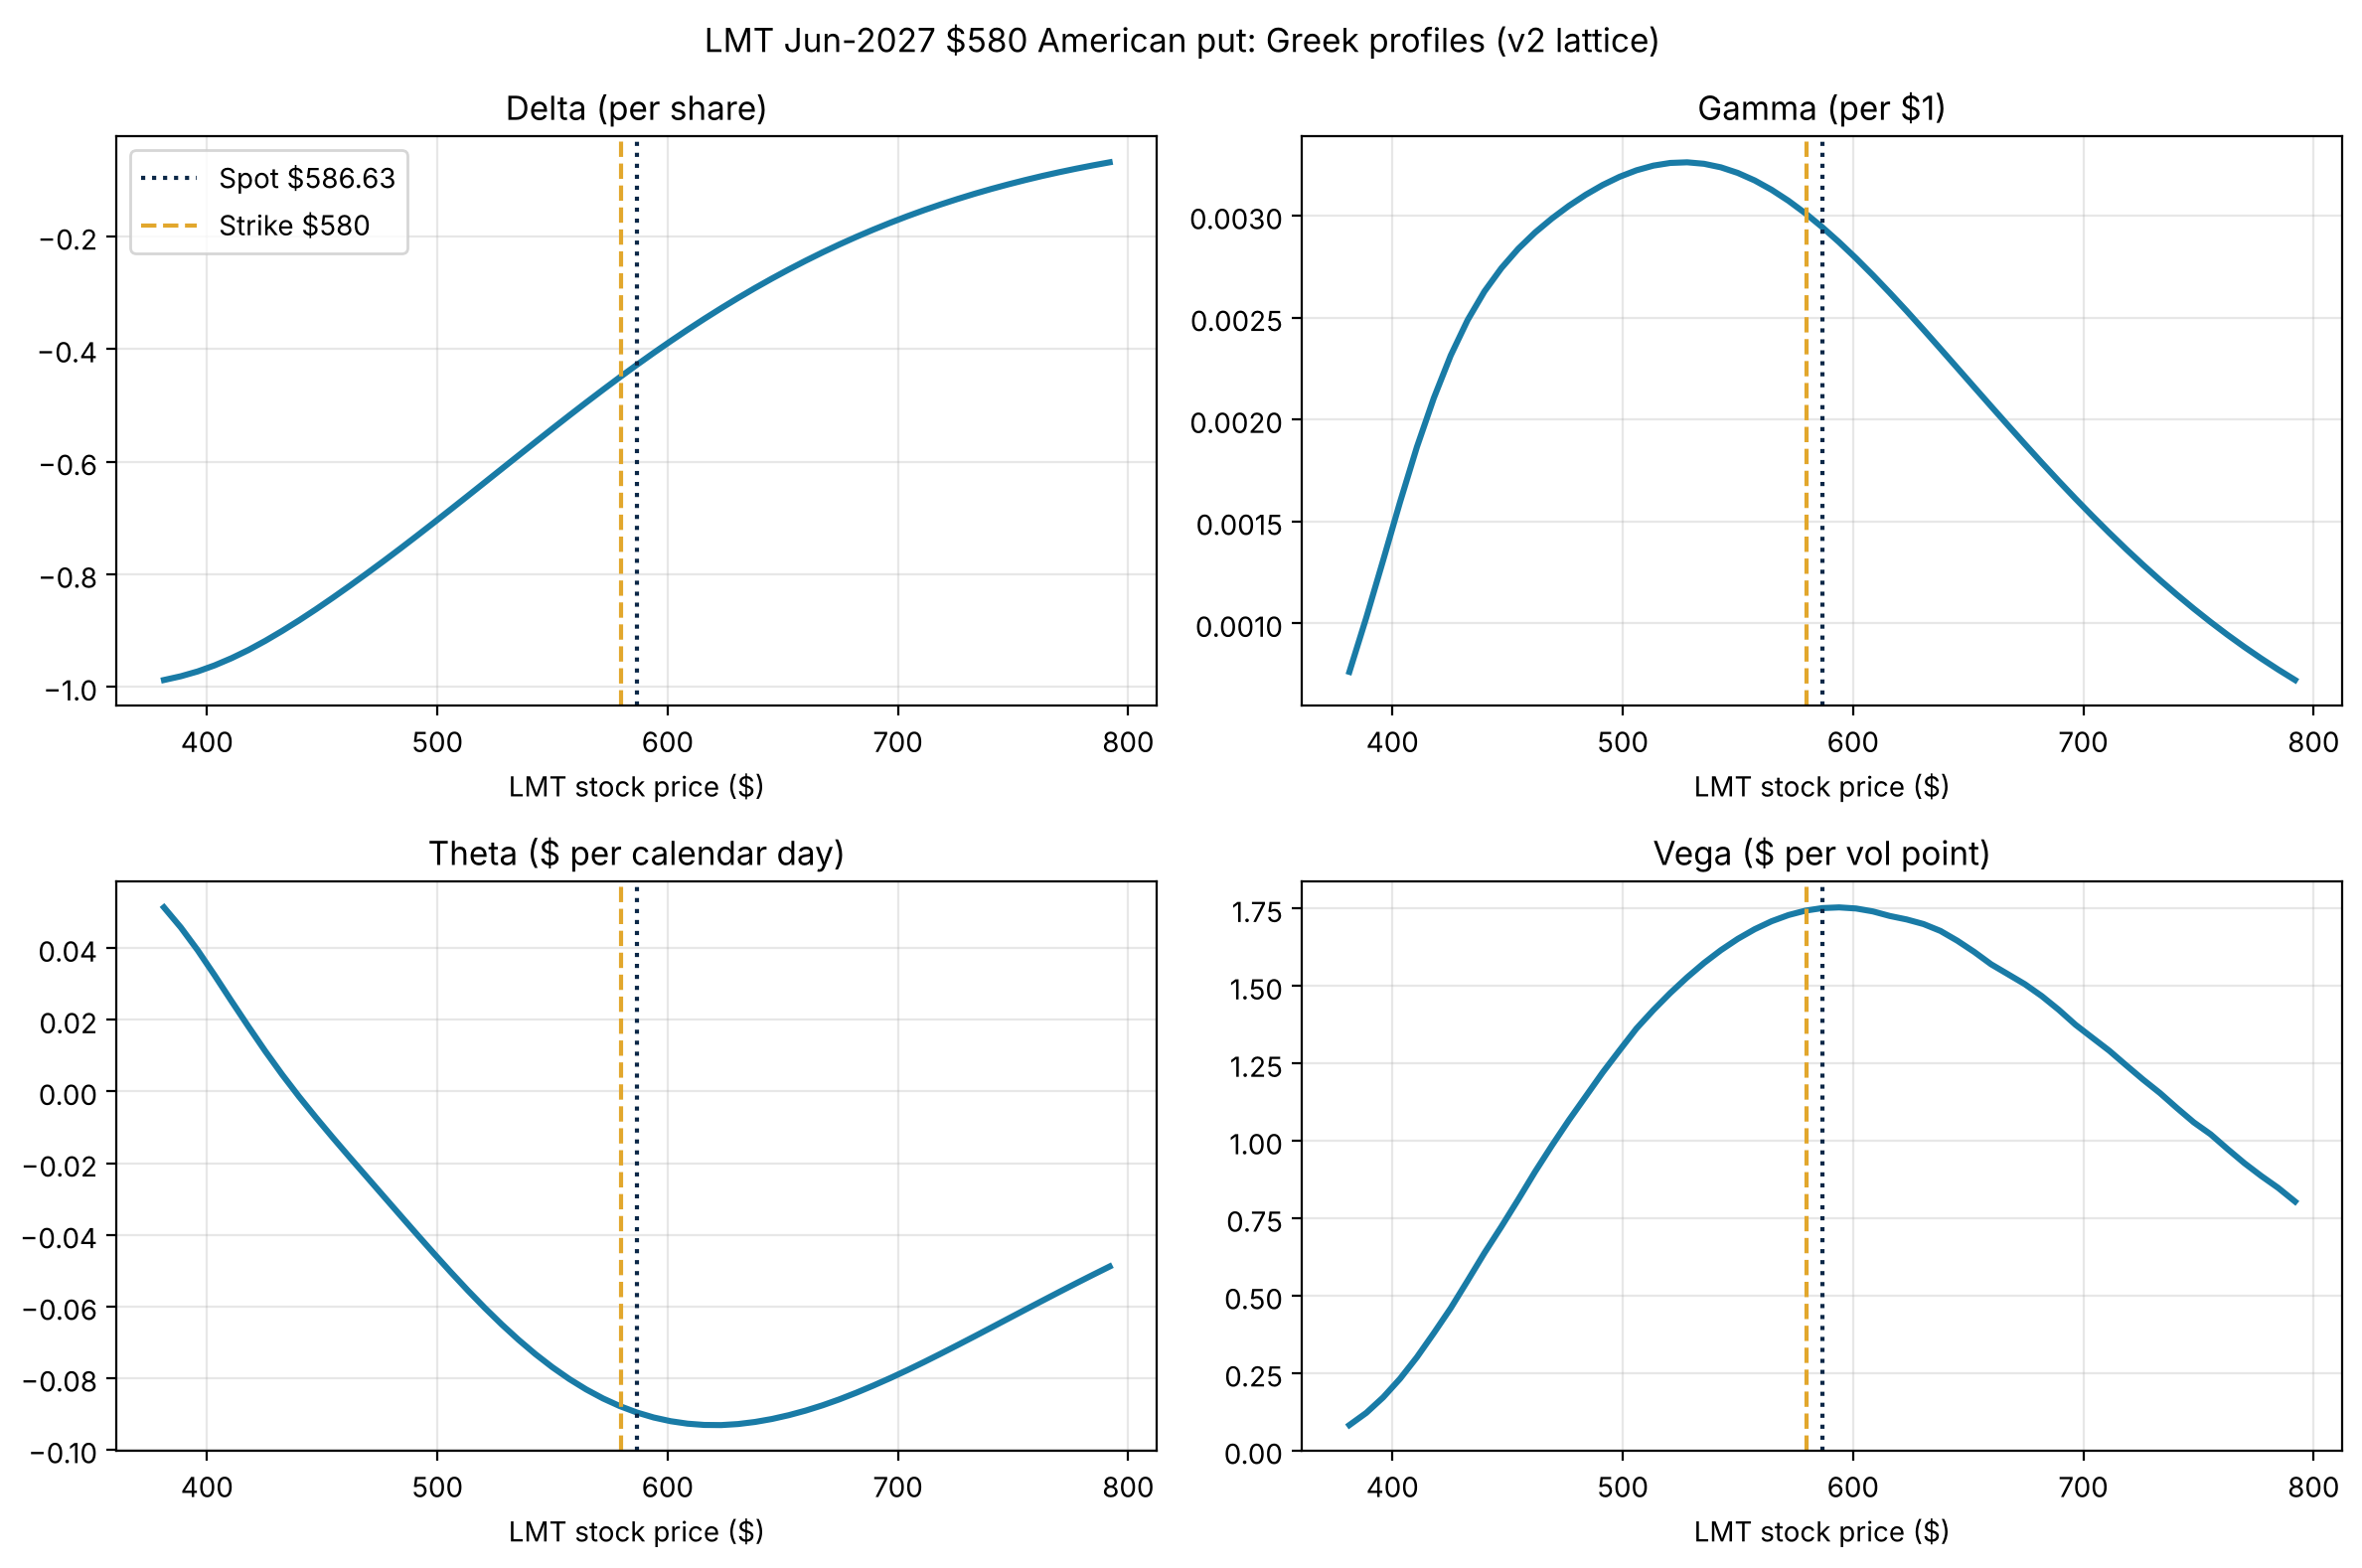

In [19]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(2,2,figsize=(12,8))
for a,(col,lab) in zip(ax.flat,[('delta','Delta (per share)'),('gamma','Gamma (per $1)'),('theta_day','Theta ($ per calendar day)'),('vega_point','Vega ($ per vol point)')]):
    a.plot(profile_S.spot,profile_S[col],lw=2.2,color='#197ba6'); a.axvline(M['spot'],color='#0b2747',ls=':',label=f"Spot ${M['spot']:.2f}")
    a.axvline(M['strike'],color='#e2a72d',ls='--',label=f"Strike ${M['strike']:.0f}"); a.set_title(lab); a.set_xlabel('LMT stock price ($)'); a.grid(alpha=.3)
ax[0,0].legend(); fig.suptitle('LMT Jun-2027 $580 American put: Greek profiles (v2 lattice)'); fig.tight_layout(); plt.show()

## 14. Risk profile, Module 5 checks and export

In [20]:
hedge_shares=-delta*CONTRACT_MULTIPLIER
rehedge_after_10=lattice_node_greeks(spot=M['spot']-10)[0]
risk={
 'value_per_share':V0,'value_per_contract':V0*CONTRACT_MULTIPLIER,
 'delta_share_equivalent_per_contract':delta*CONTRACT_MULTIPLIER,
 'delta_hedge_shares_per_contract':hedge_shares,
 'delta_after_10_drop':rehedge_after_10,
 'hedge_shares_after_10_drop':-rehedge_after_10*CONTRACT_MULTIPLIER,
 'daily_theta_per_contract':theta_year/365*CONTRACT_MULTIPLIER,
 'vega_per_point_per_contract':vega/100*CONTRACT_MULTIPLIER,
 'rho_per_pp_per_contract':rho/100*CONTRACT_MULTIPLIER,
 'gamma_per_contract':gamma*CONTRACT_MULTIPLIER,
 'one_sd_daily_move':M['spot']*M['volatility']/math.sqrt(252),
}
risk['one_sd_daily_move_pnl_delta']=delta*risk['one_sd_daily_move']*CONTRACT_MULTIPLIER
risk['vega_vs_theta_days']=abs((vega/100)/(theta_year/365))
greek_checks={
 'delta_in_put_range':bool(-1<=delta<=0),
 'gamma_nonnegative':bool(gamma>=0),
 'vega_positive':bool(vega>0),
 'rho_negative_for_put':bool(rho<0),
 'units_reported':True,
 'primary_vs_finite_difference_compared':bool(len(val)>=6),
 'all_fd_within_tolerance':bool((val.status=='PASS').all()),
 'approximations_vs_full_repricing_compared':bool(len(approx)>0 and len(multi)>0),
 'same_inputs_and_valuation_date':bool(abs(V0-v2_value)<1e-12),
 'per_share_and_per_contract_distinguished':True,
 'profile_delta_in_range':bool(profile_S.delta.between(-1-1e-9,1e-9).all()),
 'profile_gamma_nonnegative':bool((profile_S.gamma>=-1e-9).all()),
}
assert all(greek_checks[k] for k in ['delta_in_put_range','gamma_nonnegative','vega_positive','rho_negative_for_put','same_inputs_and_valuation_date','profile_delta_in_range'])
print('Delta hedge for one long put: buy %.1f shares; after a $10 drop the hedge grows to %.1f shares (rebalance needed).'%(hedge_shares,risk['hedge_shares_after_10_drop']))
print('One-standard-deviation daily move: $%.2f -> delta P&L per contract about $%.0f, versus theta of $%.2f per day.'%(risk['one_sd_daily_move'],risk['one_sd_daily_move_pnl_delta'],risk['daily_theta_per_contract']))
greek_checks

Delta hedge for one long put: buy 42.8 shares; after a $10 drop the hedge grows to 45.8 shares (rebalance needed).
One-standard-deviation daily move: $11.22 -> delta P&L per contract about $-480, versus theta of $-8.95 per day.


{'delta_in_put_range': True,
 'gamma_nonnegative': True,
 'vega_positive': True,
 'rho_negative_for_put': True,
 'units_reported': True,
 'primary_vs_finite_difference_compared': True,
 'all_fd_within_tolerance': True,
 'approximations_vs_full_repricing_compared': True,
 'same_inputs_and_valuation_date': True,
 'per_share_and_per_contract_distinguished': True,
 'profile_delta_in_range': True,
 'profile_gamma_nonnegative': True}

In [21]:
def records(df): return json.loads(df.to_json(orient='records'))
results['greeks']={
 'model':'v2 escrowed-dividend American CRR, 500/501-step average','value':V0,'contract_multiplier':CONTRACT_MULTIPLIER,
 'delta':delta,'gamma':gamma,'theta_year':theta_year,'theta_day':theta_year/365,'vega':vega,'vega_point':vega/100,'rho':rho,'rho_pp':rho/100,
 'bumps':{'spot_pct':0.01,'sigma_primary':H_SIGMA,'sigma_check':0.005,'rate_primary':H_RATE,'rate_check':0.0005,'theta_days':1},
 'table':records(greeks),'benchmark':records(bench.fillna(0)),'validation':records(val),'bump_table':records(bump_table),
 'vega_bumps':records(vega_rho_bumps),'rho_bumps':records(rho_bumps),
 'approximation':records(approx),'multi_factor':[{'scenario':k,**{kk:float(vv) for kk,vv in v.items()}} for k,v in multi.to_dict('index').items()],
 'profile_S':records(profile_S),'profile_vol':records(profile_vol),'profile_T':records(profile_T),'delta_by_T':{'spot':[float(x) for x in S_grid],**delta_by_T},
 'risk':risk,'checks':greek_checks}
(DOCS/'model_results.json').write_text(json.dumps(results,indent=2))
print('Exported Greeks to docs/model_results.json')

Exported Greeks to docs/model_results.json


### 14.1 Interpreting the risk profile for this contract

- **Delta (−0.428 per share, −42.8 share-equivalents per contract).** Delta is the most important current sensitivity. A one-standard-deviation daily move in LMT (about ±$11.22 at 30.36% volatility) changes the contract value by about ∓$480. That is more than 50 times one day of theta. Owning one contract is economically similar to being short about 43 LMT shares near today's price.
- **Gamma (0.0029 per share).** Delta moves by about 0.029 for every $10 move in LMT. Gamma is highest around $530, *below* the strike, so the exposure grows fastest if LMT falls. After a $10 drop, a delta hedge has to go from about 42.8 to 45.8 shares. The hedge is not "set and forget"; it needs rebalancing as the price moves.
- **Vega ($1.75 per vol point; $175 per contract).** This is the second most important risk. A 3-point jump in implied volatility around defense-budget headlines is worth about as much as a $12 stock move. One vol point is worth about 20 days of time decay.
- **Theta (−$0.090 per day; −$8.95 per contract).** Time decay is modest today because 220 days remain, and it accelerates sharply in the final weeks (Section 13). Deep in the money, theta turns *positive*: the escrowed dividends and the right to exercise early make waiting worth more than the lost time value.
- **Rho (−$1.55 per percentage point).** This is the smallest sensitivity. A 25 bp change in rates moves the put by only about $0.39. The American put's rho (−155) is smaller in size than the European put's (−176), because early exercise lets the holder collect the strike, and the interest on it, sooner.
- **Early exercise.** Even 35% below today's price, the lattice does not exercise immediately. With $10.66 of dividends still to come, waiting is better, which is why the early-exercise premium is only $0.50.

## 15. Integrated decision memo

> **DRAFT. AI-assisted (see the AI-use disclosure below). Revise it in my own words and confirm every number before submitting. The DCF and comparable-company figures in the Equity Valuation paragraph must come from my own earlier LMT model.**

### Equity Valuation
Lockheed Martin traded at $586.63 on November 9, 2026, after a 6.9% one-day drop on November 4 tied to concerns that the next defense budget could be cut. My DCF value is **$[DCF] per diluted share** and my comparable-company value is **$[COMPS]**, versus 15 current analyst targets with a mean of $644.47 and a median of $650.00. [Explain here whether my DCF sits above or below the market and which two assumptions (for example, the F-35 and missile-program revenue growth, the margin path, WACC, or terminal growth) drive the difference.] The analysts' median implies about 11% upside over twelve months, so the sell side and the market disagree mainly on how durable defense spending will be.

### Option Valuation
The selected contract is the June 17, 2027 $580 American put (220 days; quoted at $48.70 bid / $51.60 ask, midpoint $50.15, open interest 99). The five analyst-informed states put 90% of the subjective weight at prices above the strike. Only the severe-bear state ($562.80) pays off, so the discounted scenario payoff is just $1.68 ($0.77 if the 12-month targets are scaled to the option's 0.60-year life). This is a belief-based expected payoff, not a price. The analysts' targets have a log dispersion of 9.1%, versus 23.6% implied by 30.36% volatility over the option's life, and the analyst weights are not risk-neutral. The CRR model prices the put at $48.33 (v1, continuous yield). After I modelled the three $3.60 dividends as dated cash payments (v2), the value rises to $49.05, of which $0.50 is early-exercise premium. The market midpoint is $1.10 above the v2 value, and the v2 value sits inside the bid-ask range. Backing out volatility gives 30.98% at the midpoint (30.16% at the bid, 31.81% at the ask), so the gap is about 0.6 vol points, smaller than the spread itself.

### Greeks and Risk Profile
Per share, delta is −0.428, gamma is 0.0029, theta is −$0.090 per calendar day, vega is $1.75 per vol point and rho is −$1.55 per percentage point. Per contract (×100), that is −42.8 share-equivalents, −$8.95 per day, $175 per vol point and −$155 per point of rates. Delta is the most important current sensitivity: a typical one-day move in LMT (±$11.22) changes the contract by about $480, far more than a day of decay. Gamma peaks near $530, below the strike, so the put's exposure grows fastest if LMT keeps falling. Vega is the second-largest risk: a 3-point jump in implied volatility on budget news would add about $525 per contract. As expiration approaches, theta and gamma both rise sharply near the strike.

### Approximation and Model Risk
The Greeks were confirmed by full repricing: every finite-difference check differs by less than 0.5%. Bump sizes below 0.5% of spot produce noisy lattice gamma, which I report rather than hide. For a ±5% move, delta alone misses by about $1.30 per share, while delta-gamma misses by $0.05. At ±20%, delta-gamma misses by $1.41 to $3.14 because gamma changes along the way. A small combined shock (S −1%, vol +1 point, one day, rates +10 bp) is predicted within $0.01 (0.3%). A large combined shock is off by 9% because the inputs interact and a dividend date passes. Other model risks: two of the three dividend dates are estimates; a single flat volatility ignores the skew (the June 2027 puts trade between roughly 29.7% and 31.9% IV); the spread is 5.8% of the midpoint and the last trade was November 5; the targets' 12-month horizon does not match the option's 0.60 years; and the escrowed-dividend lattice applies the quoted volatility to S* rather than S.

### Conclusion
**Principal claim:** under my stated assumptions, the LMT June 2027 $580 put trades about $1.10 (2.2%) above my v2 model value of $49.05, but inside the bid-ask range, so I do not call it overpriced. The market is pricing about 31% volatility. **Important number:** delta of −0.43, about −43 share-equivalents per contract. **Material uncertainty:** the future volatility of LMT around defense-budget negotiations, which drives both vega and the risk-neutral value. **Reversal condition:** if the contract's midpoint implies a volatility outside the 30.16%–31.81% bid-ask IV band measured here (re-estimated with the same v2 model), or if LMT closes below $535, where gamma and delta change materially, I would rerun the model and revisit this conclusion.

## 16. AI-use disclosure

**Tool:** Claude (Anthropic), used through a Claude in Chrome browser session.
**How it was used:** finding and recording market inputs from public pages (Yahoo Finance option chain and quote, MarketBeat/Benzinga analyst targets, FRED Treasury yields); writing and debugging the v2 escrowed-dividend lattice, the Greek calculations, the finite-difference validation, the approximation tests and the Greeks dashboard (`docs/greeks.html`); and drafting the decision memo.
**How the output was verified:** the notebook's own checks (put-call parity, bounds, convergence at 25–1,000 steps, p*, American ≥ European); Greeks cross-checked against independent finite differences and a closed-form European benchmark; the European lattice was reconciled with the closed form to within $0.01; and every input was re-checked against the source pages listed in `data/source_documentation.csv`.
**What I revised or rejected:** [Fill in, e.g., which memo sentences I rewrote, which assumptions I changed, and anything I rejected, such as using stale analyst targets or a continuous dividend yield.]
**Responsibility:** I reviewed the data, assumptions and conclusions and can defend them. The template's validation tests were not altered.